# Indian Electricity Demand Forecasting — Updated Notebook

Forecast the next 24 hourly demand values from the previous 168 hours. Compare a PyTorch MLP with persistence, daily seasonal-naive, and weekly seasonal-naive baselines.

**Workbook structure confirmed from your sample:** data are on `Sheet1`; row 1 has SCADA tag names, row 2 has measurement labels, and observations begin on row 3. The target is selected by its measurement label `NLDC_DEMAND|P`. Source readings are every 5 minutes and are aggregated to hourly means.

Put the downloaded `.xlsx` files in `data/raw/`. For a meaningful multi-year forecast project, download all available monthly files. The code below warns about long gaps and never makes forecast windows across missing-hour gaps.

## 1. Imports and settings

In [2]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import mean_absolute_error, mean_squared_error

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

DATA_DIR = Path("D:/AI Engineer/project/electric")
OUTPUT_DIR = Path("D:/AI Engineer/project/electric/outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

FILE_PATTERN = "*.xlsx"
SHEET_NAME = "Sheet1"
TIMESTAMP_LABEL = "Time"
TARGET_LABEL = "NLDC_DEMAND|P"
LOOKBACK = 168
HORIZON = 24
TRAIN_FRACTION = 0.70
VAL_FRACTION = 0.15

Device: cpu


## 2. Inspect input files

In [3]:
files = sorted(DATA_DIR.glob(FILE_PATTERN))
print("Data folder:", DATA_DIR.resolve())
print("Excel files found:", len(files))
for p in files:
    print(f"  {p.name} ({p.stat().st_size:,} bytes)")
if not files:
    raise FileNotFoundError(
        f"No .xlsx files found in {DATA_DIR.resolve()}. "
        "Download the dataset workbooks and place them in data/raw/."
    )

xls = pd.ExcelFile(files[0])
print("Sheets in first workbook:", xls.sheet_names)
sample = pd.read_excel(files[0], sheet_name=SHEET_NAME, header=None)
print("Sheet shape:", sample.shape)
display(sample.iloc[:2, :].T.rename(columns={0: "tag_name", 1: "measurement_label"}).head(20))

Data folder: D:\AI Engineer\project\electric
Excel files found: 6
  October 2021.xlsx (1,585,454 bytes)
  October 2022.xlsx (47,752,660 bytes)
  October 2023.xlsx (49,491,582 bytes)
  September 2021.xlsx (1,467,124 bytes)
  September 2022.xlsx (1,633,338 bytes)
  September 2023.xlsx (47,366,872 bytes)
Sheets in first workbook: ['_osi_config', 'Sheet1', 'Sheet2']
Sheet shape: (8930, 15)


,tag_name,measurement_label
0,Time,NaN
1,SCADA/ANALOG/044MQ068/0,TOTAL_THM_ONLY|P
2,SCADA/ANALOG/044MQ062/0,TOTAL_NLDC_HYD|P
3,SCADA/ANALOG/044MQ063/0,TOTAL_NLDC_GAS|P
4,SCADA/ANALOG/044MQ064/0,TOTAL_NLDC_NPC|P
5,SCADA/ANALOG/044MQ070/0,ALL_INDIA_WIND|P
6,SCADA/ANALOG/044MQ206/0,ALL_IND_SOLAR|P
7,NaN,Solar
8,NaN,Solar+Wind
9,NaN,Total


## 3. Read timestamp and demand by measurement label

In [4]:
def load_one_workbook(path):
    sheet = pd.read_excel(path, sheet_name=SHEET_NAME, header=None)
    if sheet.shape[0] < 3:
        raise ValueError("Sheet has fewer than three rows.")

    tag_names = sheet.iloc[0].tolist()
    measurement_labels = sheet.iloc[1].tolist()
    time_cols = [i for i, v in enumerate(tag_names)
                 if str(v).strip().lower() == TIMESTAMP_LABEL.lower()]
    target_cols = [i for i, v in enumerate(measurement_labels)
                   if str(v).strip() == TARGET_LABEL]

    if len(time_cols) != 1:
        raise ValueError(f"Expected one '{TIMESTAMP_LABEL}' column; found {len(time_cols)}.")
    if len(target_cols) != 1:
        raise ValueError(f"Expected one '{TARGET_LABEL}' measurement; found {len(target_cols)}.")

    out = sheet.iloc[2:, [time_cols[0], target_cols[0]]].copy()
    out.columns = ["timestamp", "demand"]
    out["timestamp"] = pd.to_datetime(out["timestamp"], errors="coerce")
    out["demand"] = pd.to_numeric(out["demand"], errors="coerce")
    out = out.dropna(subset=["timestamp", "demand"])
    out["source_file"] = path.name
    return out

frames, skipped = [], []
for path in files:
    try:
        part = load_one_workbook(path)
        if len(part):
            frames.append(part)
            print(f"Loaded {path.name}: {len(part):,} rows")
        else:
            skipped.append((path.name, "No valid rows"))
    except Exception as exc:
        skipped.append((path.name, str(exc)))
        print(f"Skipping {path.name}: {exc}")

if not frames:
    raise ValueError(
        f"No usable workbook rows found. Check sheet '{SHEET_NAME}' and label '{TARGET_LABEL}'."
    )

raw = pd.concat(frames, ignore_index=True).sort_values("timestamp")
print("Combined rows:", len(raw))
print("Date range:", raw.timestamp.min(), "to", raw.timestamp.max())
print("Duplicate timestamps:", int(raw.timestamp.duplicated().sum()))
display(raw.head())

Loaded October 2021.xlsx: 8,928 rows
Loaded October 2022.xlsx: 267,840 rows
Loaded October 2023.xlsx: 267,840 rows
Loaded September 2021.xlsx: 8,640 rows
Loaded September 2022.xlsx: 8,640 rows
Loaded September 2023.xlsx: 259,200 rows
Combined rows: 821088
Date range: 2021-09-01 00:00:00 to 2023-10-31 23:59:50
Duplicate timestamps: 0


,timestamp,demand,source_file
544608,2021-09-01 00:00:00,161787.062500,September 2021.xlsx
544609,2021-09-01 00:05:00,161141.453125,September 2021.xlsx
544610,2021-09-01 00:10:00,161562.953125,September 2021.xlsx
544611,2021-09-01 00:15:00,162257.453125,September 2021.xlsx
544612,2021-09-01 00:20:00,161090.453125,September 2021.xlsx


## 4. Resample five-minute observations to hourly demand

Hourly calendar range: 2021-09-01 00:00:00 to 2023-10-31 23:00:00
Hourly slots: 18984
Usable hourly values: 4396
Missing hourly slots: 14588
Gaps longer than one hour: 2


,gap
timestamp,
2022-09-01,303 days 23:00:00
2023-09-01,303 days 23:00:00


C:\Users\Sicario\AppData\Local\Temp\ipykernel_812\3576506443.py:23: UserWarning: Long gaps detected. Download all monthly files for a continuous study period. Windows will not cross long gaps.
  warnings.warn(


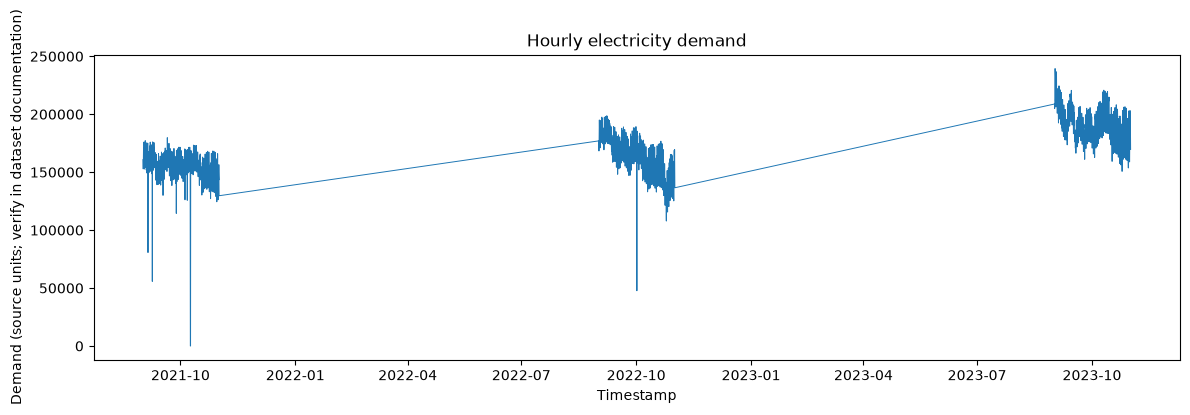

In [5]:
# Repeated timestamps for this same target are averaged before hourly aggregation.
five_min = raw.groupby("timestamp")["demand"].mean().sort_index()
hourly = five_min.resample("1h").mean()

# Fill only short internal gaps (up to 2 hours); long gaps stay missing.
hourly = hourly.interpolate(method="time", limit=2, limit_area="inside")
hourly.name = "demand"
valid = hourly.dropna()

if valid.empty:
    raise ValueError("No hourly demand values remain after resampling.")

print("Hourly calendar range:", hourly.index.min(), "to", hourly.index.max())
print("Hourly slots:", len(hourly))
print("Usable hourly values:", len(valid))
print("Missing hourly slots:", int(hourly.isna().sum()))

gaps = valid.index.to_series().diff().dropna()
long_gaps = gaps[gaps > pd.Timedelta(hours=1)]
print("Gaps longer than one hour:", len(long_gaps))
if len(long_gaps):
    display(long_gaps.sort_values(ascending=False).head(10).to_frame("gap"))
    warnings.warn(
        "Long gaps detected. Download all monthly files for a continuous study period. "
        "Windows will not cross long gaps."
    )

plt.figure(figsize=(12, 4))
plt.plot(valid.index, valid.values, linewidth=0.7)
plt.title("Hourly electricity demand")
plt.xlabel("Timestamp")
plt.ylabel("Demand (source units; verify in dataset documentation)")
plt.tight_layout()
plt.show()

## 5. Build leakage-aware chronological windows

In [6]:
# Split the data into contiguous segments so windows cannot cross long missing periods.
segment_id = valid.index.to_series().diff().ne(pd.Timedelta(hours=1)).cumsum()
segments = []
for _, seg in valid.groupby(segment_id):
    seg = seg.sort_index()
    if len(seg) >= LOOKBACK + HORIZON:
        segments.append(seg)

print("Usable contiguous segments:", len(segments))
print("Segment lengths (hours):", [len(s) for s in segments])
if not segments:
    raise ValueError(
        f"No continuous segment has at least {LOOKBACK + HORIZON} hours. "
        "Check the input files or download more complete monthly data."
    )

# Cutoffs use actual usable timestamps, not the full calendar with missing years.
valid_times = valid.index.sort_values()
train_cut_time = valid_times[int(len(valid_times) * TRAIN_FRACTION)]
val_cut_time = valid_times[min(int(len(valid_times) * (TRAIN_FRACTION + VAL_FRACTION)),
                               len(valid_times) - 1)]
print("Training target cutoff:", train_cut_time)
print("Validation target cutoff:", val_cut_time)

# Fit scaling on training-period values only.
train_values = valid.loc[valid.index < train_cut_time].to_numpy(dtype=np.float64)
if not len(train_values):
    raise ValueError("Training period is empty.")
mean = float(train_values.mean())
std = float(train_values.std())
if not np.isfinite(std) or std == 0:
    raise ValueError("Training standard deviation is invalid or zero.")
print(f"Training scaling mean={mean:.3f}, std={std:.3f}")

X_train_list, y_train_list = [], []
X_val_list, y_val_list = [], []
X_test_list, y_test_list = [], []

for seg in segments:
    vals = seg.to_numpy(dtype=np.float64)
    times = seg.index
    for start in range(LOOKBACK, len(seg) - HORIZON + 1):
        target_start = times[start]
        target_end = times[start + HORIZON - 1]
        x = ((vals[start - LOOKBACK:start] - mean) / std).astype(np.float32)
        y = ((vals[start:start + HORIZON] - mean) / std).astype(np.float32)

        if target_end < train_cut_time:
            X_train_list.append(x); y_train_list.append(y)
        elif target_start >= train_cut_time and target_end < val_cut_time:
            X_val_list.append(x); y_val_list.append(y)
        elif target_start >= val_cut_time:
            X_test_list.append(x); y_test_list.append(y)

def stack(items, width):
    return np.stack(items).astype(np.float32) if items else np.empty((0, width), dtype=np.float32)

X_train, y_train = stack(X_train_list, LOOKBACK), stack(y_train_list, HORIZON)
X_val, y_val = stack(X_val_list, LOOKBACK), stack(y_val_list, HORIZON)
X_test, y_test = stack(X_test_list, LOOKBACK), stack(y_test_list, HORIZON)

for label, x, y in [("Train", X_train, y_train), ("Validation", X_val, y_val), ("Test", X_test, y_test)]:
    print(f"{label}: X={x.shape}, y={y.shape}")

if min(len(X_train), len(X_val), len(X_test)) == 0:
    raise ValueError(
        "A split has zero windows. Download more monthly files or inspect the printed "
        "segment lengths. Do not train until all three splits contain samples."
    )

Usable contiguous segments: 3
Segment lengths (hours): [1466, 1466, 1464]
Training target cutoff: 2023-09-07 01:00:00
Validation target cutoff: 2023-10-04 12:00:00
Training scaling mean=162242.668, std=19995.996
Train: X=(2550, 168), y=(2550, 24)
Validation: X=(613, 168), y=(613, 24)
Test: X=(637, 168), y=(637, 24)


## 6. Train PyTorch MLP with early stopping

Early stopping at epoch 23
Best epoch: 13
Best validation MSE (scaled units): 0.098097


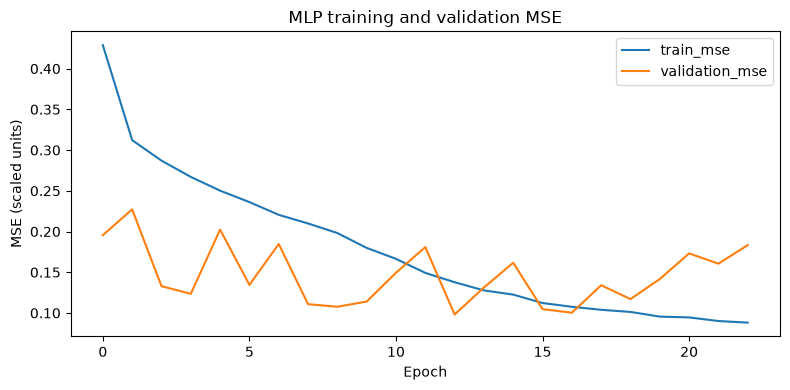

In [7]:
class DemandMLP(nn.Module):
    def __init__(self, lookback=LOOKBACK, horizon=HORIZON):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(lookback, 256), nn.ReLU(), nn.Dropout(0.1),
            nn.Linear(256, 128), nn.ReLU(), nn.Dropout(0.1),
            nn.Linear(128, horizon)
        )
    def forward(self, x):
        return self.net(x)

model = DemandMLP().to(DEVICE)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
loss_fn = nn.MSELoss()
loader = DataLoader(
    TensorDataset(torch.from_numpy(X_train), torch.from_numpy(y_train)),
    batch_size=64, shuffle=True
)
Xv, yv = torch.from_numpy(X_val).to(DEVICE), torch.from_numpy(y_val).to(DEVICE)

best_loss, best_state, best_epoch = float("inf"), None, 0
patience, wait = 10, 0
history = {"train_mse": [], "validation_mse": []}

for epoch in range(1, 101):
    model.train()
    batch_losses = []
    for xb, yb in loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        optimizer.zero_grad()
        loss = loss_fn(model(xb), yb)
        loss.backward()
        optimizer.step()
        batch_losses.append(float(loss.item()))

    model.eval()
    with torch.no_grad():
        val_loss = float(loss_fn(model(Xv), yv).item())

    history["train_mse"].append(float(np.mean(batch_losses)))
    history["validation_mse"].append(val_loss)

    if val_loss < best_loss:
        best_loss, best_epoch = val_loss, epoch
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        wait = 0
    else:
        wait += 1
        if wait >= patience:
            print("Early stopping at epoch", epoch)
            break

if best_state is None:
    raise RuntimeError("No best model state was saved.")
model.load_state_dict(best_state)
print("Best epoch:", best_epoch)
print("Best validation MSE (scaled units):", round(best_loss, 6))

pd.DataFrame(history).plot(figsize=(8, 4), title="MLP training and validation MSE")
plt.xlabel("Epoch"); plt.ylabel("MSE (scaled units)")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "mlp_training_curve.png", dpi=160)
plt.show()

torch.save({
    "model_state_dict": model.state_dict(),
    "lookback": LOOKBACK, "horizon": HORIZON,
    "mean": mean, "std": std, "best_epoch": best_epoch
}, OUTPUT_DIR / "demand_mlp.pt")

## 7. Evaluate baselines and the PyTorch MLP

In [8]:
y_test_original = y_test * std + mean

baseline_predictions = {
    "Persistence": np.repeat(X_test[:, -1:], HORIZON, axis=1) * std + mean,
    "Daily seasonal naive": X_test[:, -24:] * std + mean,
    "Weekly seasonal naive": X_test[:, -168:-144] * std + mean,
}

model.eval()
with torch.no_grad():
    mlp_pred = model(torch.from_numpy(X_test).to(DEVICE)).cpu().numpy() * std + mean

predictions = {**baseline_predictions, "PyTorch MLP": mlp_pred}

def metrics(actual, pred):
    actual, pred = np.asarray(actual).ravel(), np.asarray(pred).ravel()
    denom = np.sum(np.abs(actual))
    wape = 100 * np.sum(np.abs(actual - pred)) / denom if denom else np.nan
    return {
        "MAE": mean_absolute_error(actual, pred),
        "RMSE": np.sqrt(mean_squared_error(actual, pred)),
        "WAPE_percent": wape
    }

results = pd.DataFrame([
    {"model": name, **metrics(y_test_original, pred)}
    for name, pred in predictions.items()
]).sort_values("MAE").reset_index(drop=True)

display(results.round(3))
results.to_csv(OUTPUT_DIR / "test_model_comparison.csv", index=False)

lead_rows = []
for h in range(HORIZON):
    for name, pred in predictions.items():
        lead_rows.append({
            "model": name,
            "forecast_hour": h + 1,
            "MAE": mean_absolute_error(y_test_original[:, h], pred[:, h])
        })
lead_metrics = pd.DataFrame(lead_rows)
lead_metrics.to_csv(OUTPUT_DIR / "test_metrics_by_forecast_hour.csv", index=False)
display(lead_metrics.head(12))

,model,MAE,RMSE,WAPE_percent
0,Daily seasonal naive,3845.034,5341.791,2.035
1,PyTorch MLP,5992.575,7793.968,3.171
2,Weekly seasonal naive,8845.589,11010.246,4.681
3,Persistence,14365.509,17870.783,7.602


,model,forecast_hour,MAE
0,Persistence,1,3570.290771
1,Daily seasonal naive,1,3832.331543
2,Weekly seasonal naive,1,8753.473633
3,PyTorch MLP,1,4484.143555
4,Persistence,2,6401.800781
5,Daily seasonal naive,2,3836.502441
6,Weekly seasonal naive,2,8755.041992
7,PyTorch MLP,2,4614.000000
8,Persistence,3,8970.165039
9,Daily seasonal naive,3,3841.949463


## 8. Plot an example forecast and list outputs

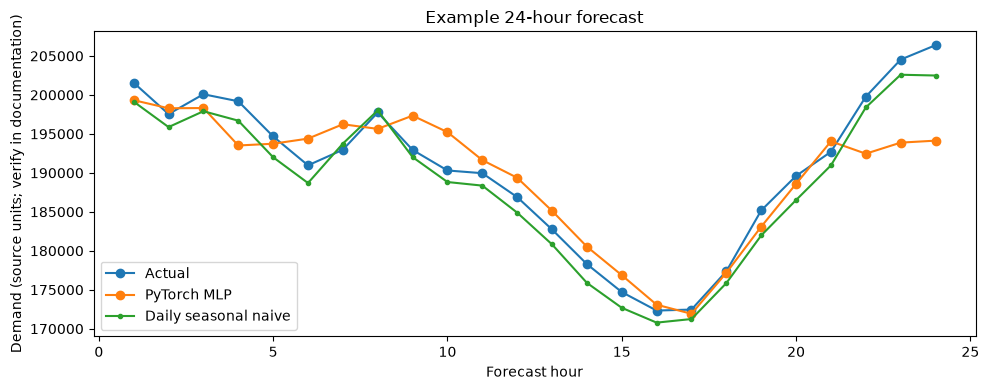

Outputs saved to: D:\AI Engineer\project\electric\outputs
 - demand_mlp.pt
 - example_24_hour_forecast.png
 - mlp_training_curve.png
 - test_metrics_by_forecast_hour.csv
 - test_model_comparison.csv


In [9]:
plt.figure(figsize=(10, 4))
plt.plot(range(1, HORIZON + 1), y_test_original[0], marker="o", label="Actual")
plt.plot(range(1, HORIZON + 1), mlp_pred[0], marker="o", label="PyTorch MLP")
plt.plot(range(1, HORIZON + 1), baseline_predictions["Daily seasonal naive"][0],
         marker=".", label="Daily seasonal naive")
plt.xlabel("Forecast hour")
plt.ylabel("Demand (source units; verify in documentation)")
plt.title("Example 24-hour forecast")
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "example_24_hour_forecast.png", dpi=160)
plt.show()

print("Outputs saved to:", OUTPUT_DIR.resolve())
for p in sorted(OUTPUT_DIR.glob("*")):
    print(" -", p.name)

## 9. Reporting notes

- Lower MAE and RMSE indicate better forecasts; WAPE is expressed as a percentage.
- The model and baselines are evaluated in original demand units after reversing the training-only scaling.
- Confirm the dataset's units and full date coverage from its documentation before writing your report.
- If you only have a few isolated monthly files, results are not representative of continuous multi-year forecasting. Obtain the full set of monthly files and rerun all cells from the beginning.